# Resolución patentes — Benja — Opción A: más ejemplos
Suma patentes auxiliares reales y variantes artificiales a las referencias del reconocimiento.

In [1]:
import os, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
import modelo_benja as M

P = M.P          # patentes.py original, sin cambios

SALIDA = os.path.join(M.RAIZ, "images", "resolucion_patentes_benja_opcion_a")

## Parte 1 — Patentes auxiliares
Placas del mismo diseño bajadas de Wikimedia Commons. `images/auxiliares/auxiliares.csv` guarda el texto, la fuente, la licencia y la verificación de cada una.

aux_01_OBO342.jpg    OBO342   se usa: si  CC BY 4.0     Dickelbers
aux_02_GYV900.jpg    GYV900   se usa: si  CC BY 4.0     Dickelbers
aux_03_BVX427.jpg    BVX427   se usa: si  CC BY-SA 2.0  Jerry "Woody" (Flickr)
aux_04_TML094.jpg    TML094   se usa: si  CC BY-SA 3.0  Letdorf
aux_05_NVZ087.jpg    NVZ087   se usa: si  CC BY-SA 4.0  Quilmeño89
aux_06_IKR638.jpg    IKR638   se usa: si  CC BY 4.0     Dickelbers
aux_07_IVT472.jpg    IVT472   se usa: no  CC BY-SA 3.0  Plasmarelais

Diseño verificado: Placa argentina 1995-2016: caja negra, caracteres blancos en relieve, marco claro con ARGENTINA. 3 letras + 3 números.


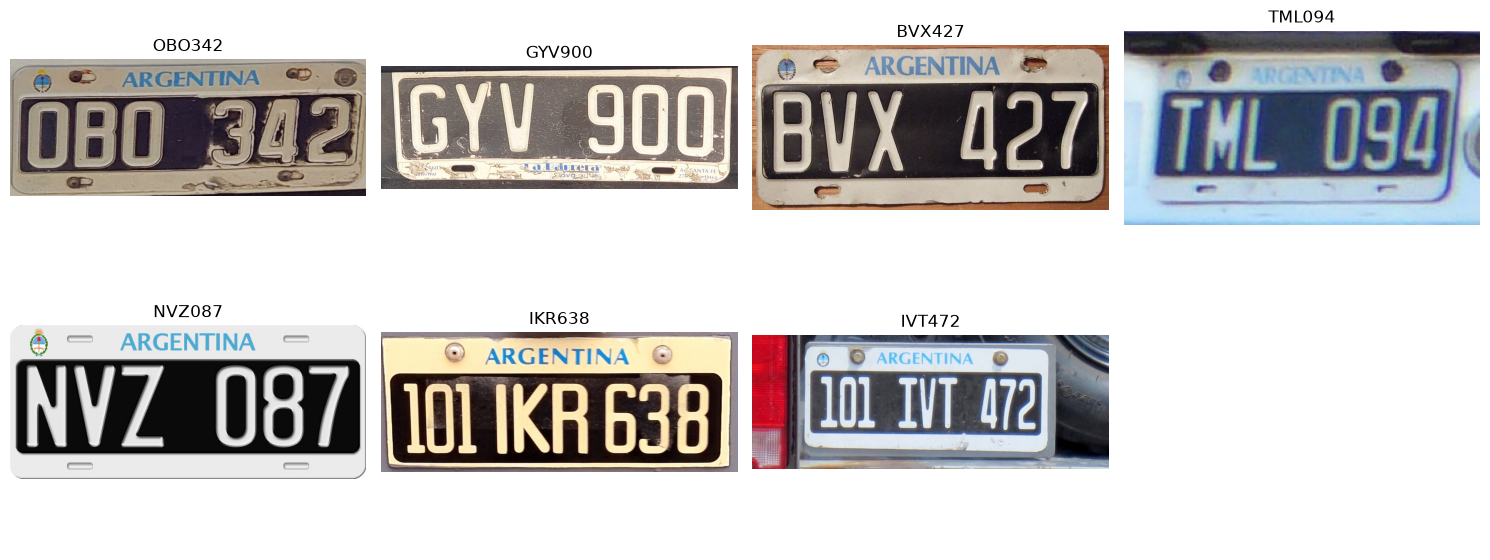

In [2]:
filas = M.leer_auxiliares()
for f in filas:
    print(f"{f['archivo']:<20} {f['texto']:<8} se usa: {f['usar_en_modelo']:<3} {f['licencia']:<13} {f['autor']}")
print("\nDiseño verificado:", filas[0]["diseno_verificado"])

fig, ejes = plt.subplots(2, 4, figsize=(15, 6))
for e, f in zip(ejes.ravel(), filas):
    e.imshow(cv2.cvtColor(cv2.imread(os.path.join(M.RUTA_AUX, f["archivo"])), cv2.COLOR_BGR2RGB)); e.set_title(f["texto"])
for e in ejes.ravel(): e.axis("off")
plt.tight_layout(); plt.show()

## Parte 2 — Segmentación de las auxiliares
Mismo modelo que las patentes de la consigna. Se revisa que las 6 cajas queden bien.

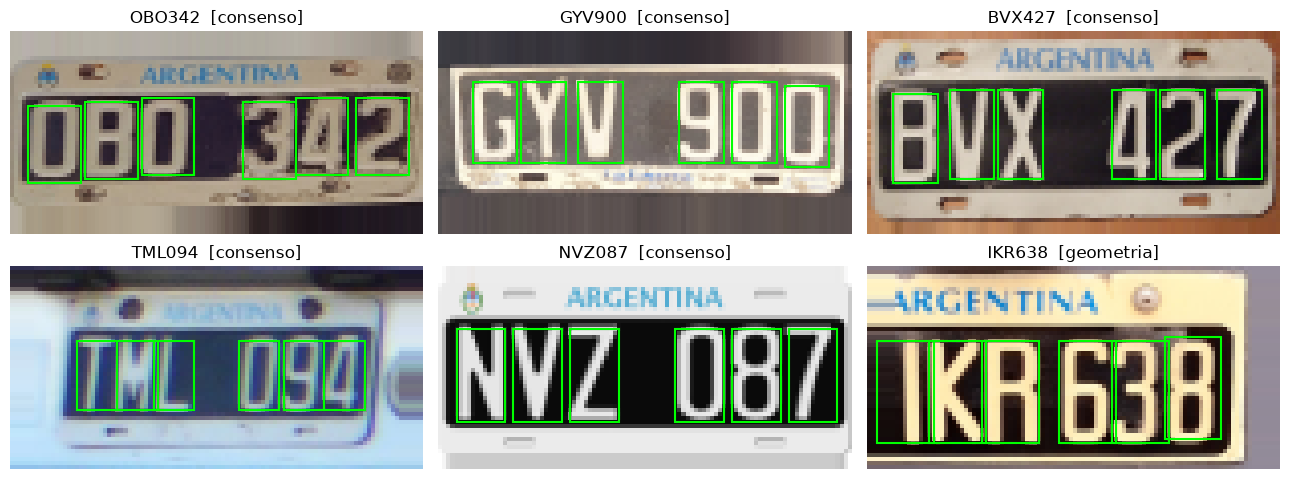

In [3]:
aux = M.cargar_auxiliares()
fig, ejes = plt.subplots(2, 3, figsize=(13, 5))
for e, a in zip(ejes.ravel(), aux):
    e.imshow(cv2.cvtColor(a["rotada"], cv2.COLOR_BGR2RGB))
    for c in a["cajas"]:
        e.add_patch(plt.Rectangle((c.x, c.y), c.w, c.h, fill=False, edgecolor="lime", linewidth=1.5))
    e.set_title(f"{a['texto']}  [{a['metodo']}]"); e.axis("off")
plt.tight_layout(); plt.show()

## Parte 3 — Comparación de referencias
Lee las 12 patentes con cuatro conjuntos de referencias, dejando afuera la patente que se lee.

In [4]:
tp = M.cargar_tp()
base = {i: P.analizar_foto(M.ruta_foto(i)) for i in M.FOTOS}
configs = {"base (11 de la consigna)":    M.armar_referencias(tp),
           "+ auxiliares":                M.armar_referencias(tp, aux),
           "+ variantes artificiales":    M.armar_referencias(tp, (), aumentar=True),
           "+ auxiliares + variantes":    M.armar_referencias(tp, aux, aumentar=True)}
resultados = {nombre: M.evaluar(tp, refs) for nombre, refs in configs.items()}
for nombre, (_, res) in resultados.items():
    print(f"{nombre:<26} letras {res['letras']:>2}/36   números {res['numeros']:>2}/36   completas {res['completas']:>2}/12")

base (11 de la consigna)   letras 24/36   números 29/36   completas  0/12
+ auxiliares               letras 25/36   números 31/36   completas  2/12
+ variantes artificiales   letras 27/36   números 31/36   completas  3/12
+ auxiliares + variantes   letras 29/36   números 34/36   completas  5/12


## Parte 4 — Resultado por patente
Usa auxiliares + variantes. Guarda una imagen por patente y un `resumen.csv` en `images/resolucion_patentes_benja_opcion_a/`.

In [5]:
lecturas, res = resultados["+ auxiliares + variantes"]
for i in M.FOTOS:
    print(f"img{i:02d}  leída {lecturas[i]}  real {M.ETIQUETAS[i]}  {res['aciertos'][i]}/6")
M.guardar_resultados(SALIDA, tp, base, lecturas, "   |   opción A")
print(f"\nletras {res['letras']}/36   números {res['numeros']}/36   patentes completas {res['completas']}/12")
print("guardado en", SALIDA)

img01  leída BOF817  real BUF817  5/6
img02  leída GXQ796  real GXQ798  5/6
img03  leída DMH024  real DMH024  6/6
img04  leída LNE988  real LHE986  4/6
img05  leída FJY344  real FJY344  6/6
img06  leída LEH992  real LEH992  6/6
img07  leída LOD123  real LOD123  6/6
img08  leída JNO337  real JMO337  5/6
img09  leída FFO765  real FFD765  5/6
img10  leída OOD322  real DOA322  4/6
img11  leída GMO569  real GMQ569  5/6
img12  leída BQX387  real BQX387  6/6



letras 29/36   números 34/36   patentes completas 5/12
guardado en C:\Users\Benja\Documents\Facultad\3\cuatri_dos\imagenes\tp_procesamiento_de_imagenes_2\images\resolucion_patentes_benja_opcion_a
